<a href="https://colab.research.google.com/github/gabimazzo-coder/Entrega-Final/blob/main/Pre_entrega_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMPORTO LIBRERIAS Y CARGO DATASET


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Configuración visual
sns.set_theme(style="whitegrid")

# Cargar el dataset de Propinas ('tips') de Seaborn
df = sns.load_dataset('tips')

# Mostrar las primeras filas
df.head()


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Exploración inicial y limpieza básica

In [2]:
# Revisar tipos de datos y valores nulos
print("--- INFORMACIÓN DEL DATASET ---")
df.info()

print("\n--- VALORES NULOS ---")
print(df.isnull().sum())

# Verificar si hay filas duplicadas
print(f"\nFilas duplicadas: {df.duplicated().sum()}")
df = df.drop_duplicates()


--- INFORMACIÓN DEL DATASET ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

--- VALORES NULOS ---
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Filas duplicadas: 1


 Análisis de Distribución

 Gráficos de barras para variables categóricas

/tmp/ipykernel_3067/1677327004.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='day', palette='viridis', ax=axes[0])
/tmp/ipykernel_3067/1677327004.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='time', palette='magma', ax=axes[1])


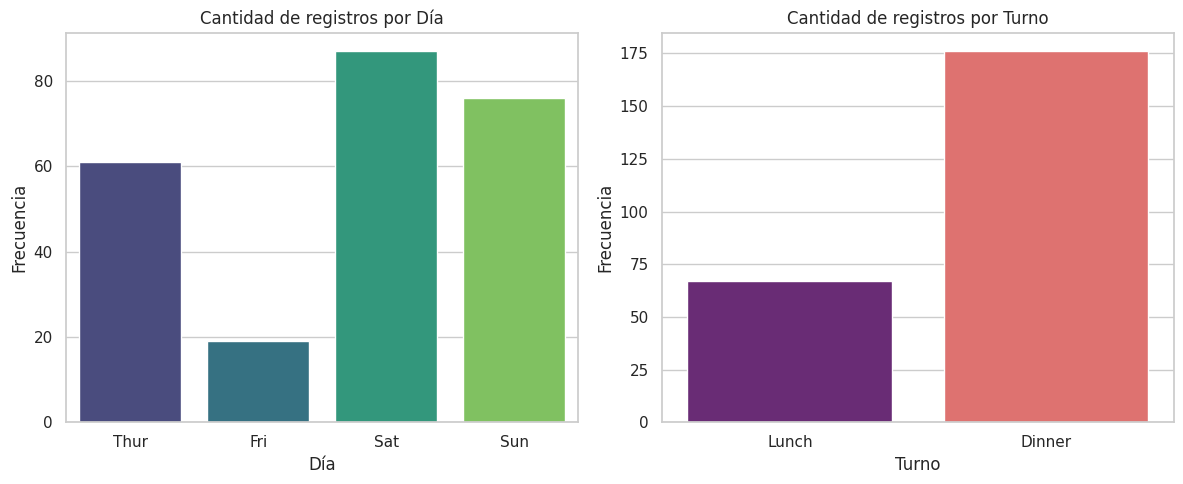

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1: Días de la semana
sns.countplot(data=df, x='day', palette='viridis', ax=axes[0])
axes[0].set_title('Cantidad de registros por Día')
axes[0].set_xlabel('Día')
axes[0].set_ylabel('Frecuencia')

# Gráfico 2: Momento del día (Almuerzo vs Cena)
sns.countplot(data=df, x='time', palette='magma', ax=axes[1])
axes[1].set_title('Cantidad de registros por Turno')
axes[1].set_xlabel('Turno')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()



Asimetría (Skewness) y Curtosis (Kurtosis)



In [4]:
variables_numericas = ['total_bill', 'tip']

for col in variables_numericas:
    asimetria = df[col].skew()
    curtosis = df[col].kurt()
    print(f"Variable: {col}")
    print(f"  -> Asimetría (Skewness): {asimetria:.2f}")
    print(f"  -> Curtosis (Kurtosis):  {curtosis:.2f}\n")


Variable: total_bill
  -> Asimetría (Skewness): 1.13
  -> Curtosis (Kurtosis):  1.21

Variable: tip
  -> Asimetría (Skewness): 1.46
  -> Curtosis (Kurtosis):  3.63



Tanto total_bill (~1.13) como tip (~1.46) tienen asimetría positiva (valores mayores a 0). Esto significa que la cola de la distribución se extiende hacia la derecha, indicando que la mayoría de las cuentas y propinas son bajas o moderadas, pero existen algunos consumos muy altos.

•
	• La curtosis es positiva (leptocúrtica, especialmente en tip con ~3.64), lo que indica una mayor concentración de datos cerca de la media y presencia de colas pesadas (valores extremos).


 Detección de Outliers


 Boxplots y Violin Plots



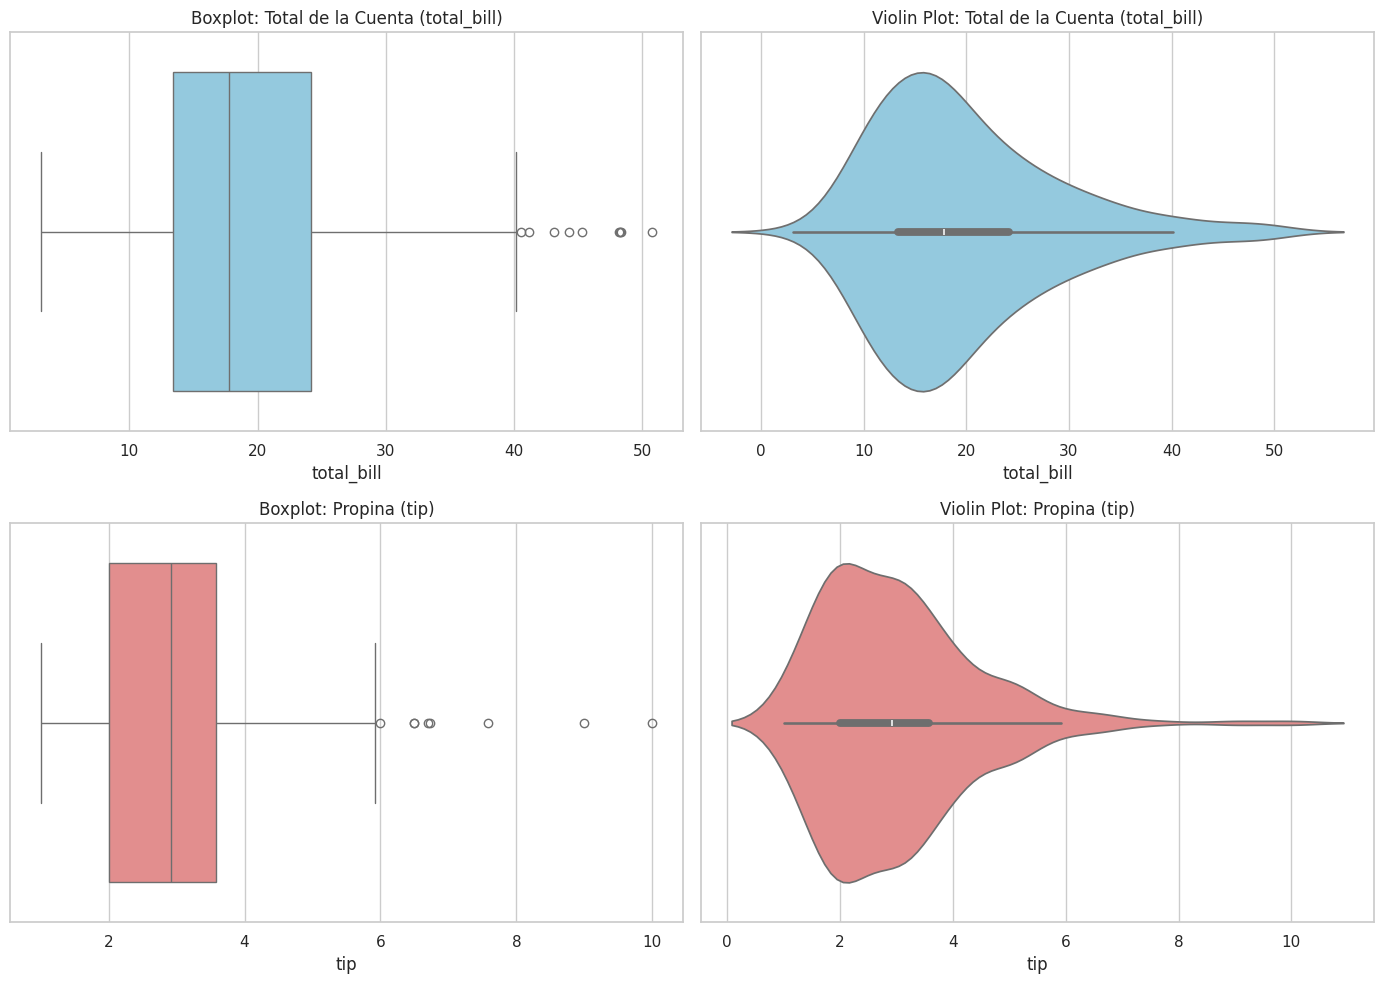

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Boxplot y Violinplot para Total Bill
sns.boxplot(data=df, x='total_bill', color='skyblue', ax=axes[0, 0])
axes[0, 0].set_title('Boxplot: Total de la Cuenta (total_bill)')

sns.violinplot(data=df, x='total_bill', color='skyblue', ax=axes[0, 1])
axes[0, 1].set_title('Violin Plot: Total de la Cuenta (total_bill)')

# Boxplot y Violinplot para Tip
sns.boxplot(data=df, x='tip', color='lightcoral', ax=axes[1, 0])
axes[1, 0].set_title('Boxplot: Propina (tip)')

sns.violinplot(data=df, x='tip', color='lightcoral', ax=axes[1, 1])
axes[1, 1].set_title('Violin Plot: Propina (tip)')

plt.tight_layout()
plt.show()


Cálculo y listado de Outliers mediante IQR

In [6]:
def detectar_outliers_iqr(dataframe, columna):
    Q1 = dataframe[columna].quantile(0.25)
    Q3 = dataframe[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = dataframe[(dataframe[columna] < limite_inferior) | (dataframe[columna] > limite_superior)]

    print(f"=== OUTLIERS EN '{columna.upper()}' ===")
    print(f"Límite inferior: {limite_inferior:.2f} | Límite superior: {limite_superior:.2f}")
    print(f"Cantidad de outliers detectados: {len(outliers)}\n")
    return outliers

# Filtrar y mostrar los registros outliers de 'total_bill'
outliers_cuenta = detectar_outliers_iqr(df, 'total_bill')
display(outliers_cuenta)

# Filtrar y mostrar los registros outliers de 'tip'
outliers_propina = detectar_outliers_iqr(df, 'tip')
display(outliers_propina)


=== OUTLIERS EN 'TOTAL_BILL' ===
Límite inferior: -2.81 | Límite superior: 40.37
Cantidad de outliers detectados: 9



,total_bill,tip,sex,smoker,day,time,size
59,48.27,6.73,Male,No,Sat,Dinner,4
102,44.30,2.50,Female,Yes,Sat,Dinner,3
142,41.19,5.00,Male,No,Thur,Lunch,5
156,48.17,5.00,Male,No,Sun,Dinner,6
170,50.81,10.00,Male,Yes,Sat,Dinner,3
182,45.35,3.50,Male,Yes,Sun,Dinner,3
184,40.55,3.00,Male,Yes,Sun,Dinner,2
197,43.11,5.00,Female,Yes,Thur,Lunch,4
212,48.33,9.00,Male,No,Sat,Dinner,4


=== OUTLIERS EN 'TIP' ===
Límite inferior: -0.36 | Límite superior: 5.94
Cantidad de outliers detectados: 8



,total_bill,tip,sex,smoker,day,time,size
23,39.42,7.58,Male,No,Sat,Dinner,4
47,32.40,6.00,Male,No,Sun,Dinner,4
59,48.27,6.73,Male,No,Sat,Dinner,4
141,34.30,6.70,Male,No,Thur,Lunch,6
170,50.81,10.00,Male,Yes,Sat,Dinner,3
183,23.17,6.50,Male,Yes,Sun,Dinner,4
212,48.33,9.00,Male,No,Sat,Dinner,4
214,28.17,6.50,Female,Yes,Sat,Dinner,3
